# Part II - Bay Wheels Trip Behavior: Who Rides, When, and for How Long
## by Hsin-Wen Chang

## Investigation Overview

This presentation summarizes key behavioral differences in Bay Wheels trips for February 2019, with a focus on duration and demand patterns by rider type.

### Executive Summary
- Trip durations are strongly right-skewed, but typical rides are short.
- Subscribers account for most trips and generally take shorter rides than Customers.
- Usage timing differs by segment: Subscriber demand is weekday and commute-hour dominant.

## Dataset Overview and Executive Summary

The dataset contains one row per trip, including duration, timestamps, station details, and rider profile fields. The selected visual sequence is designed to explain the strongest and most actionable findings from exploratory analysis in a compact story flow.

In [1]:
# import all packages and set plots to be embedded inline
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.simplefilter("ignore")
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (11, 6)

**Execution Note:** Before final export, use Restart Kernel and Run All so execution order and outputs are clean and sequential.

In [2]:
def prepare_trips(csv_name: str) -> pd.DataFrame:
    """Load and prepare trip data for explanatory visuals."""
    file_path = Path(csv_name)
    if not file_path.exists():
        raise FileNotFoundError(
            f"Could not find {csv_name}. Run this notebook from the folder containing the dataset."
        )

    df = pd.read_csv(file_path)
    df["start_time"] = pd.to_datetime(df["start_time"])
    df["duration_min"] = df["duration_sec"] / 60
    df["start_hour"] = df["start_time"].dt.hour
    df["start_day_name"] = pd.Categorical(
        df["start_time"].dt.day_name(),
        categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
        ordered=True
    )
    df["member_age"] = 2019 - df["member_birth_year"]
    df.loc[~df["member_age"].between(18, 80), "member_age"] = np.nan
    return df

df = prepare_trips("201902-fordgobike-tripdata.csv")
duration_cap = df["duration_min"].quantile(0.99)
print("Prepared rows:", len(df))

Prepared rows: 183412


## Visualization 1 - Trip Duration Is Right-Skewed (From Part I Univariate)

This figure is taken from the univariate exploration in Part I. It shows the trip-duration histogram with a mean reference line after trimming at the 99th percentile for readability.

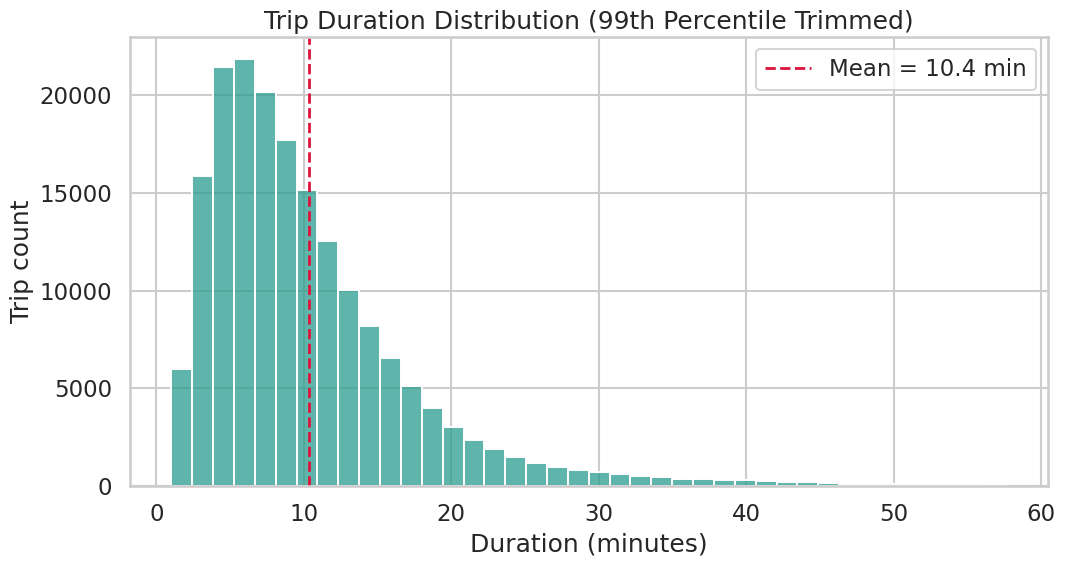

In [3]:
duration_core = df.loc[df["duration_min"] <= duration_cap, "duration_min"]

plt.figure(figsize=(11, 6))
sns.histplot(duration_core, bins=40, color="#2a9d8f")
plt.axvline(
    duration_core.mean(), color="crimson", linestyle="--", linewidth=2,
    label=f"Mean = {duration_core.mean():.1f} min"
)
plt.title("Trip Duration Distribution (99th Percentile Trimmed)")
plt.xlabel("Duration (minutes)")
plt.ylabel("Trip count")
plt.legend()
plt.tight_layout()
plt.show()

**Audience takeaway:** Most rides are short, and the right-skewed distribution confirms that long trips exist but are relatively uncommon.

## Visualization 2 - Weekday Pattern Differs by User Type (From Part I Bivariate)

This heatmap is reused from the bivariate exploration in Part I. It compares normalized weekday trip shares for Subscribers and Customers, highlighting commute-like weekday concentration among Subscribers.

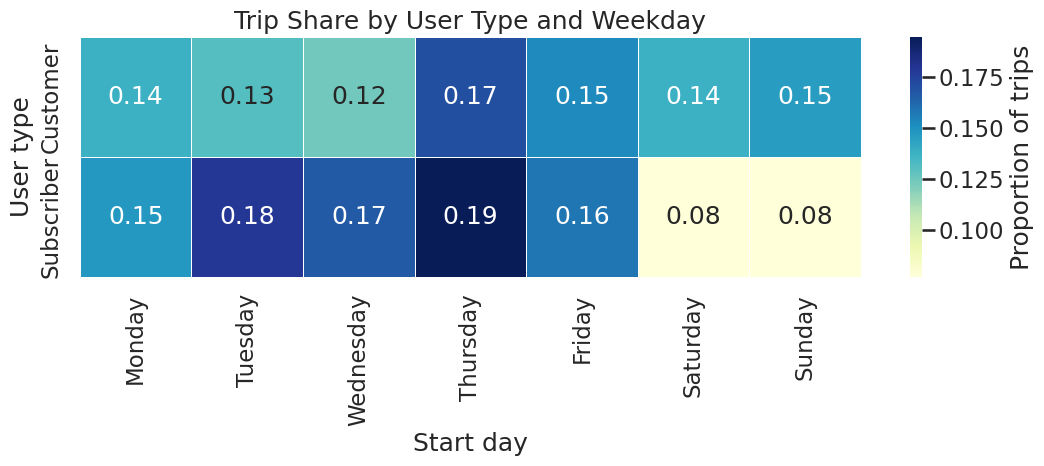

In [4]:
heat_df = (
    df.groupby(["user_type", "start_day_name"]).size()
    .groupby(level=0).transform(lambda x: x / x.sum())
    .rename("share")
    .reset_index()
    .pivot(index="user_type", columns="start_day_name", values="share")
)

plt.figure(figsize=(11, 5))
sns.heatmap(
    heat_df, cmap="YlGnBu", annot=True, fmt=".2f", linewidths=0.5,
    cbar_kws={"label": "Proportion of trips"}
    )
plt.title("Trip Share by User Type and Weekday")
plt.xlabel("Start day")
plt.ylabel("User type")
plt.tight_layout()
plt.show()

**Audience takeaway:** Subscriber behavior is weekday-concentrated, reinforcing a commute-oriented usage pattern compared with Customers.

## Visualization 3 - Age Effect Is Modest; User Type Is More Informative

To avoid overplotting in the final presentation, this chart summarizes trip duration using median values within 5-year age bins for each user type. The relatively flat age-bin profiles indicate a weak age-duration relationship, while the persistent gap between Subscriber and Customer medians shows that `user_type` is the stronger explanatory feature.

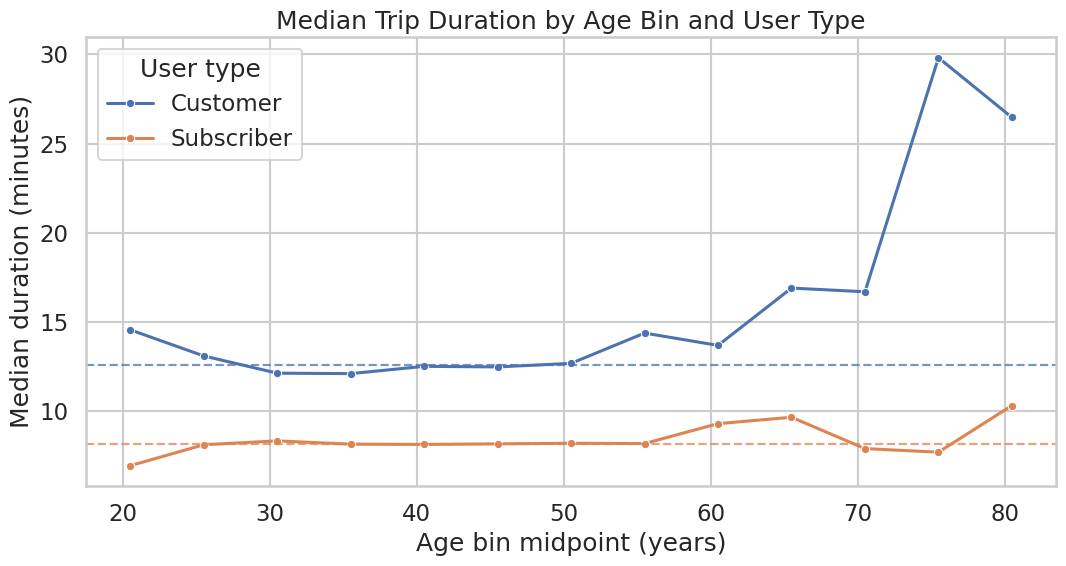

In [5]:
summary_df = df[["member_age", "duration_min", "user_type"]].dropna().copy()
summary_df = summary_df[summary_df["duration_min"] <= duration_cap]

# Build 5-year age bins for a cleaner explanatory summary.
age_bins = np.arange(18, 86, 5)
summary_df["age_bin"] = pd.cut(
    summary_df["member_age"], bins=age_bins, right=False, include_lowest=True
)
summary_df = summary_df.dropna(subset=["age_bin"])

age_profile = (
    summary_df.groupby(["age_bin", "user_type"], observed=True)["duration_min"]
    .median()
    .reset_index(name="median_duration")
)
age_profile["age_mid"] = age_profile["age_bin"].apply(lambda interval: interval.left + 2.5)

type_medians = (
    summary_df.groupby("user_type", as_index=False)["duration_min"]
    .median()
    .rename(columns={"duration_min": "overall_median"})
)

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=age_profile, x="age_mid", y="median_duration", hue="user_type",
    marker="o", linewidth=2.2, markersize=6
)

palette = dict(zip(type_medians["user_type"], sns.color_palette(n_colors=len(type_medians))))
for _, row in type_medians.iterrows():
    plt.axhline(
        row["overall_median"], linestyle="--", linewidth=1.6,
        color=palette.get(row["user_type"], "gray"), alpha=0.75
    )

plt.title("Median Trip Duration by Age Bin and User Type")
plt.xlabel("Age bin midpoint (years)")
plt.ylabel("Median duration (minutes)")
plt.legend(title="User type")
plt.tight_layout()
plt.show()

**Audience takeaway:** Age has a modest effect on duration, but the persistent separation between user-type median levels shows rider type is the stronger predictor.

## Final Takeaways

1. Rider segmentation is the clearest lens for understanding duration and demand: Subscribers are high-frequency, shorter-trip riders.
2. The duration difference is substantial and quantified: Subscriber median duration is **8.17** minutes versus **13.20** minutes for Customers; Subscriber mean duration is **10.67** minutes versus **23.87** minutes for Customers.
3. Time-of-week structure, especially weekday commute peaks, provides strong behavioral signal in system usage.
4. Demographics such as age add context but are less explanatory than rider type and temporal patterns for this dataset.

This explanatory notebook focuses on finalized insights selected from the exploratory notebook and presents them in a concise executive format.